In [ ]:

# Cell 1: Import libraries required for regression
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [ ]:

# Cell 2: Create a dataset of study hours and exam marks
data = {
    "Study_Hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Marks":       [12, 18, 28, 35, 45, 52, 60, 68, 78, 85]
}

df = pd.DataFrame(data)
# Display the dataset
print(df)


   Study_Hours  Marks
0            1     12
1            2     18
2            3     28
3            4     35
4            5     45
5            6     52
6            7     60
7            8     68
8            9     78
9           10     85


In [3]:

# Cell 3: Separate input feature (X) and target variable (y)

X = df[["Study_Hours"]]
y = df["Marks"]

print("Features:")
print(X)

print("\nTarget:")
print(y)


Features:
   Study_Hours
0            1
1            2
2            3
3            4
4            5
5            6
6            7
7            8
8            9
9           10

Target:
0    12
1    18
2    28
3    35
4    45
5    52
6    60
7    68
8    78
9    85
Name: Marks, dtype: int64


In [4]:

# Cell 4: Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 8
Testing samples: 2


In [5]:

# Cell 5: Create and train the regression model

model = LinearRegression()

# Learn the relationship between study hours and marks
model.fit(X_train, y_train)

print("Model training completed!")
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)


Model training completed!
Slope: 8.094827586206899
Intercept: 3.603448275862057


In [6]:

# Cell 6: Predict marks for the testing dataset

y_pred = model.predict(X_test)

# Compare actual marks with predicted marks
comparison = pd.DataFrame({
    "Study_Hours": X_test["Study_Hours"].to_numpy(),
    "Actual_Marks": y_test.to_numpy(),
    "Predicted_Marks": np.round(y_pred, 2)
})

print(comparison)


   Study_Hours  Actual_Marks  Predicted_Marks
0            9            78            76.46
1            2            18            19.79


In [7]:

# Cell 7: Calculate Mean Absolute Error (MAE)

mae = mean_absolute_error(y_test, y_pred)

print("MAE:", round(mae, 2))


MAE: 1.67


In [8]:

# Cell 8: Calculate Mean Squared Error (MSE) and Root Mean Squared Error (RMSE)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))


MSE: 2.8
RMSE: 1.67


In [9]:

# Cell 9: Evaluate how well the model explains variation in marks

r2 = r2_score(y_test, y_pred)

print("R2 Score:", round(r2, 3))


R2 Score: 0.997


In [10]:

# Cell 10: Predict exam marks for a student who studies for 7.5 hours

new_student = pd.DataFrame({
    "Study_Hours": [7.5]
})

predicted_marks = model.predict(new_student)

print("Study Hours:", new_student["Study_Hours"].iloc[0])
print("Predicted Marks:", round(predicted_marks[0], 2))


Study Hours: 7.5
Predicted Marks: 64.31


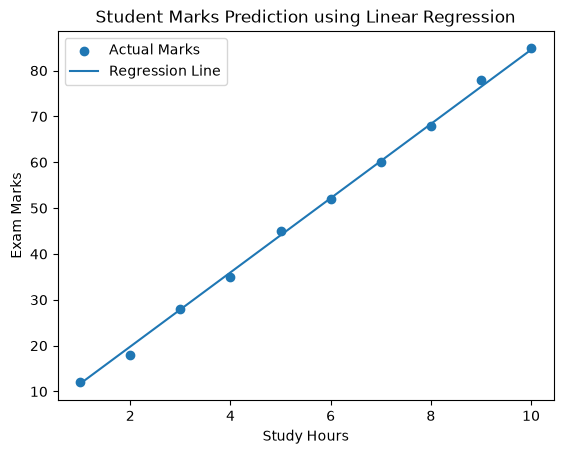

In [ ]:

# Cell 11: Plot the dataset and the fitted regression line
import matplotlib.pyplot as plt
# Show the observed data points
plt.scatter(X["Study_Hours"], y, label="Actual Marks")

# Draw the regression line across the range of study hours
X_line = pd.DataFrame({
    "Study_Hours": np.linspace(
        X["Study_Hours"].min(),
        X["Study_Hours"].max(),
        100
    )
})
plt.plot(
    X_line["Study_Hours"],
    model.predict(X_line),
    label="Regression Line"
)
plt.xlabel("Study Hours")
plt.ylabel("Exam Marks")
plt.title("Student Marks Prediction using Linear Regression")
plt.legend()
plt.show()
